<a href="https://colab.research.google.com/github/BenFreilichUVA/ds2002-fa26/blob/main/2026_11_13_%E2%80%94_Visualization_Challenge_%E2%80%94_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Visualization Challenge

**Lab — 2026-11-13 · Fall 2026**  

---

## Lab 11 — Visualization Challenge

Five charts from the **same game-day sample** as Monday's lecture. Each one is graded against the **six-point rubric** from Wednesday's studio — use `score()` from that notebook or re-type it here.

| # | Criterion |
|---|---|
| 1 | Title states a finding, not a topic |
| 2 | Axes labeled with units |
| 3 | Right chart type for the question |
| 4 | Honest scale |
| 5 | Readable — sorted, no clipping, no overlap |
| 6 | No wasted ink |

Every chart needs a one-line **caption** below it saying what decision it supports.

**Due Wednesday, November 18, 11:59pm ET** in Canvas (pushed back one week for midterm presentations). Use Monday's recipes (`barh`, `lineplot`, `histplot`, `finish()`, etc.) — you do not need new chart types beyond what the cookbook already showed.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BLUE, RUST, GRAY = '#4a5d7e', '#b4553f', '#c9d0d9'
sns.set_theme(style='white')
plt.rcParams['text.parse_math'] = False

CRITERIA = [
    'title states a finding',
    'axes labeled with units',
    'right chart for the question',
    'honest scale',
    'readable',
    'no wasted ink',
]

def score(**passed):
    """score(title=False, axes=True, ...) -> prints a scored critique."""
    total = 0
    for name, ok in zip(CRITERIA, passed.values()):
        print(('PASS' if ok else 'FAIL'), '-', name)
        total += bool(ok)
    print(f'\nscore: {total}/6')
    return total


def finish(ax, title, xlabel=None, ylabel=None, fontsize=12):
    """Same helper as Monday's lecture: title, labels, spines, tight_layout."""
    ax.set_title(title, loc='left', fontsize=fontsize)
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
    ax.figure.tight_layout()


# --- game-day sample (same generator as the Monday lecture) ------------------
rng = np.random.default_rng(2026)
hours = np.arange(9, 22)
build_up = np.exp(-((hours - 14.5) ** 2) / (2 * 2.3 ** 2))
storm = np.exp(-((hours - 17.0) ** 2) / (2 * 1.5 ** 2))
GAMES = {'Sep 5': False, 'Sep 19': False, 'Oct 10': True, 'Nov 14': True}

rows = []
for game, rainy in GAMES.items():
    rain_mm = rainy * (0.4 + 3.0 * storm) * rng.gamma(10, 0.1, len(hours))
    for h, b, rain in zip(hours, build_up, rain_mm):
        n_main = rng.poisson(b * 150 + 12)
        n_rain = rng.poisson(rain * 5 + 0.2)
        cats = np.concatenate([
            rng.choice(['Food', 'Merch', 'Drink'], n_main, p=[.45, .22, .33]),
            np.repeat('RainGear', n_rain),
        ])
        rows += [(game, 'rain' if rainy else 'dry', h, round(rain, 1), c) for c in cats]

df = pd.DataFrame(rows, columns=['game', 'weather', 'hour', 'rain_mm', 'category'])
df['zone'] = rng.choice(['A', 'B', 'C'], len(df), p=[.6, .3, .1])
df['revenue'] = (
    df['category'].map({'Food': 12, 'Merch': 28, 'Drink': 6, 'RainGear': 15})
    * rng.lognormal(-0.18, 0.6, len(df))
).round(2)

print(len(df), 'orders across', df['game'].nunique(), 'games')
df.head()


4364 orders across 4 games


,game,weather,hour,rain_mm,category,zone,revenue
0,Sep 5,dry,9,0.0,Food,C,7.90
1,Sep 5,dry,9,0.0,Food,B,5.46
2,Sep 5,dry,9,0.0,Drink,A,7.93
3,Sep 5,dry,9,0.0,Drink,B,5.68
4,Sep 5,dry,9,0.0,Merch,A,12.75


### Chart 1 — revenue by category

Sorted horizontal bar. Axis from zero.

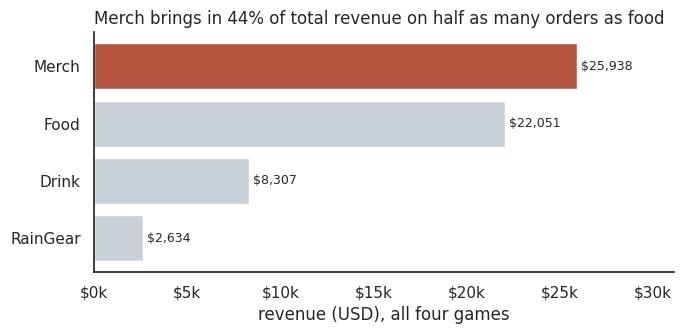

In [2]:
from matplotlib.ticker import FuncFormatter

revenue_by_category = df.groupby('category')['revenue'].sum().sort_values() # Sorted biggest on top, smallest on bottom.
colors = [RUST if c == revenue_by_category.idxmax() else GRAY for c in revenue_by_category.index] # Make the biggest category a different color.

fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.barh(revenue_by_category.index, revenue_by_category.values, color = colors)
ax.bar_label(bars, labels = [f'${v:,.0f}' for v in revenue_by_category.values], padding=3, fontsize=9)
ax.set_xlim(0, revenue_by_category.max()*1.2)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'${v / 1000:.0f}k'))
finish(ax, f"Merch brings in {revenue_by_category['Merch'] / revenue_by_category.sum():.0%} of total revenue on half as many orders as food", xlabel = 'revenue (USD), all four games')
plt.show()

In [3]:
chart1_score = score(title=True, axes=True, chart_type=True, scale=True, readable=True, ink=True)

PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6


**Caption:** Merch brings in the most money per order, as well as the most total revenue. Cutting merch stands to save on costs or to shift production towards food would lose more revenue than the plain order counts suggest.

### Chart 2 — revenue by hour

Line chart, kickoff marked at 15.5, and the title should state the staffing implication rather than describing the axes.

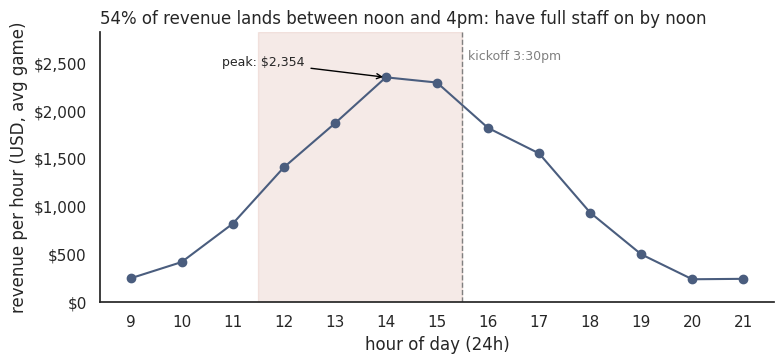

In [4]:
revenue_by_hour = df.groupby('hour')['revenue'].sum() / df['game'].nunique()   # revenue per hour, average game
peak_hour = revenue_by_hour.idxmax()
share = revenue_by_hour.loc[12:15].sum() / revenue_by_hour.sum()                   # share of the day's revenue, noon to 4pm

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(revenue_by_hour.index, revenue_by_hour.values, marker='o', color=BLUE)
ax.axvspan(11.5, 15.5, color=RUST, alpha=0.12)                              # shade the 12, 13, 14, 15 points, the ones right before kickoff
ax.axvline(15.5, ls='--', color='gray', lw=1)
ax.text(15.6, revenue_by_hour.max() * 1.12, 'kickoff 3:30pm', fontsize=9, color='gray', va='top')
ax.annotate(f'peak: ${revenue_by_hour.max():,.0f}', xy=(peak_hour, revenue_by_hour.max()),
            xytext=(peak_hour - 3.2, revenue_by_hour.max() * 1.05),
            arrowprops=dict(arrowstyle='->', color='black'), fontsize=9)
ax.set_ylim(0, revenue_by_hour.max() * 1.2)
ax.set_xticks(revenue_by_hour.index)                                            # one tick per hour, as the chart asks for
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'${v:,.0f}'))
finish(ax, f'{share:.0%} of revenue lands between noon and 4pm: have full staff on by noon',
       xlabel='hour of day (24h)', ylabel='revenue per hour (USD, avg game)')
plt.show()

In [5]:
chart2_score = score(title=True, axes=True, chart_type=True, scale=True, readable=True, ink=True)

PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6


**Caption:** Revenue climbs heavily throughout the day, most notably at 11 AM before peaking at 2 PM, an hour and a half before kickoff. Stands should be fully staffed by noon for the sales rush rather than ramping up to be prepared by kickoff, as revenue is already falling by kickoff.

### Chart 3 — revenue by zone, normalized

Raw revenue by zone mostly measures how big each zone is. Use the capacity figures below to build a second view — revenue per unit of capacity — and show both side by side.

Then say which of the two you would put in front of a manager, and for which question.

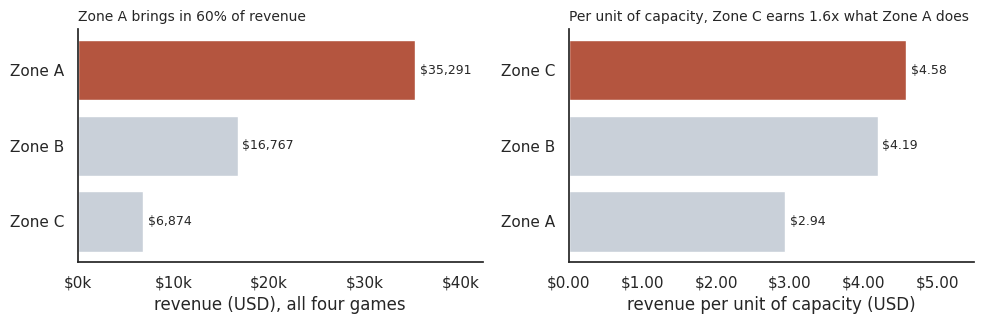

In [6]:
zone_capacity = {'A': 12000, 'B': 4000, 'C': 1500}

zones = df.groupby('zone')['revenue'].sum().to_frame('revenue')   # one row per zone
zones['capacity'] = pd.Series(zone_capacity)                      # lines up with the zone index
zones['rev_per_cap'] = zones['revenue'] / zones['capacity']

raw = zones['revenue'].sort_values()
per = zones['rev_per_cap'].sort_values()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))

# left: raw revenue
bars = axes[0].barh('Zone ' + raw.index, raw.values,
                    color=[RUST if z == raw.idxmax() else GRAY for z in raw.index])
axes[0].bar_label(bars, labels=[f'${v:,.0f}' for v in raw.values], padding=3, fontsize=9)
axes[0].set_xlim(0, raw.max() * 1.2)
axes[0].xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'${v / 1000:.0f}k'))
finish(axes[0], f"Zone A brings in {raw['A'] / raw.sum():.0%} of revenue",
       xlabel='revenue (USD), all four games', fontsize=10)

# right: revenue per unit of capacity
bars = axes[1].barh('Zone ' + per.index, per.values,
                    color=[RUST if z == per.idxmax() else GRAY for z in per.index])
axes[1].bar_label(bars, labels=[f'${v:,.2f}' for v in per.values], padding=3, fontsize=9)
axes[1].set_xlim(0, per.max() * 1.2)
axes[1].xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'${v:,.2f}'))
finish(axes[1], f"Per unit of capacity, Zone C earns {per['C'] / per['A']:.1f}x what Zone A does",
       xlabel='revenue per unit of capacity (USD)', fontsize=10)
plt.show()

In [7]:
chart3_score = score(title=True, axes=True, chart_type=True, scale=True, readable=True, ink=True)

PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6


**Caption, and which panel I would present:** While raw revenue is highest in Zone A, average revenue per unit of capacity is actually highest in Zone C. For a manager deciding where to add a stand or an extra cashier, I would want to show them the right panel. Zone A having a strong lead in total revenue is mostly due to its size, while on a per unit basis it is actually the weakest zone.

### Chart 4 — distribution, not just totals

Every chart so far is a total. **TODO:** show the *distribution* of individual order revenue with a histogram. What does the shape tell you that a category total does not?

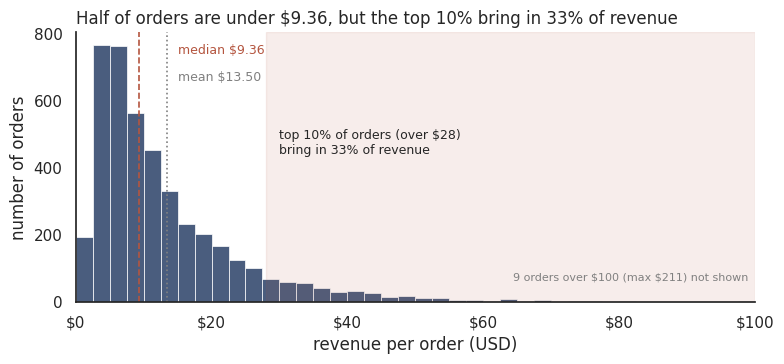

In [8]:
revenue_df = df['revenue']                                                 # one value per order
median, mean, p90 = revenue_df.median(), revenue_df.mean(), revenue_df.quantile(0.9)
top10_share = revenue_df[revenue_df >= p90].sum() / revenue_df.sum()                     # revenue share of the biggest 10% of orders
n_off = (revenue_df > 100).sum()

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(revenue_df, bins=np.arange(0, 102.5, 2.5), color=BLUE, edgecolor='white', linewidth=0.5)   # $2.50-wide bins
ax.axvspan(p90, 100, color=RUST, alpha=0.10)                        # shade the top 10%
ax.axvline(median, color=RUST, ls='--', lw=1.2)
ax.axvline(mean, color='gray', ls=':', lw=1.2)
top = ax.get_ylim()[1]
ax.text(mean + 1.5, top * 0.92, f'median ${median:.2f}', color=RUST, fontsize=9)
ax.text(mean + 1.5, top * 0.82, f'mean ${mean:.2f}', color='gray', fontsize=9)
ax.text(p90 + 2, top * 0.55, f'top 10% of orders (over ${p90:.0f})\nbring in {top10_share:.0%} of revenue', fontsize=9)
ax.text(99, top * 0.08, f'{n_off} orders over $100 (max ${revenue_df.max():.0f}) not shown',
        fontsize=8, color='gray', ha='right')
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'${v:,.0f}'))
finish(ax, f'Half of orders are under ${median:.2f}, but the top 10% bring in {top10_share:.0%} of revenue',
       xlabel='revenue per order (USD)', ylabel='number of orders')
plt.show()

In [9]:
chart4_score = score(title=True, axes=True, chart_type=True, scale=True, readable=True, ink=True)

PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6


**Caption:** A typical order is about $9, but a third of the revenue from the day comes from the biggest 10% of the orders, with the majority of those orders being merch. Losing a few big merch buyers is much more damaging to the top line than losing small food and drink orders.

### Chart 5 — your choice

**TODO:** a grouped, stacked, or scatter view that reveals something the first four do not. The finding is the point; the chart type is your call.

If you use a scatter, size or annotate the points so a reader can tell which ones carry enough data to trust.

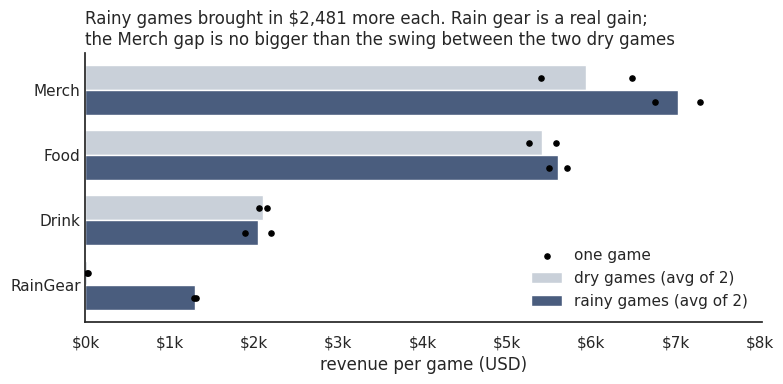

In [10]:
game_category = df.groupby(['game', 'weather', 'category'])['revenue'].sum().reset_index()   # one row per game x category
avg = game_category.groupby(['category', 'weather'])['revenue'].mean().unstack()            # per-game average, dry vs rain
avg = avg.sort_values('rain')                                                           # biggest on top

per_game_total = df.groupby(['game', 'weather'])['revenue'].sum().groupby('weather').mean()
lift = per_game_total['rain'] - per_game_total['dry']

y = np.arange(len(avg))     # one row per category
h = 0.38                    # bar thickness
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(y + h / 2, avg['dry'], height=h, color=GRAY, label='dry games (avg of 2)')
ax.barh(y - h / 2, avg['rain'], height=h, color=BLUE, label='rainy games (avg of 2)')
for weather, offset in (('dry', h / 2), ('rain', -h / 2)):                      # each single game as a dot
    pts = game_category[game_category['weather'] == weather]
    ax.scatter(pts['revenue'], pts['category'].map(dict(zip(avg.index, y))) + offset,
               color='black', s=14, zorder=3)
ax.scatter([], [], color='black', s=14, label='one game')                       # legend entry for the dots
ax.set_yticks(y, avg.index)
ax.tick_params(axis='y', length=0)
ax.set_xlim(0, game_category['revenue'].max() * 1.1)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'${v / 1000:.0f}k'))
ax.legend(frameon=False, loc='lower right')
finish(ax, f'Rainy games brought in ${lift:,.0f} more each. Rain gear is a real gain;\n'
           'the Merch gap is no bigger than the swing between the two dry games',
       xlabel='revenue per game (USD)')
plt.show()

In [11]:
chart5_score = score(title=True, axes=True, chart_type=True, scale=True, readable=True, ink=True)

PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6


**Caption:** Rainy games brought in about $2,481 more per game, but only the rain gear portion of the increase actually holds up. The merch increase is about the same size as the gap between the two dry games, so with only two games of each kind it looks like normal coincidental variation rather than a rain effect. Checking how the data was generated confirms this, since merch's share of orders doesn't depend on the weather at all. Managers should stock extra rain gear for rainy games but shouldn't plan merch inventory around the weather.

### Score your own work

**TODO:** score each chart out of 6 and fix anything under 5 before submitting.

In [12]:
scores = {
    'chart 1 (category)': chart1_score,
    'chart 2 (hour)': chart2_score,
    'chart 3 (zone)': chart3_score,
    'chart 4 (distribution)': chart4_score,
    'chart 5 (your choice)': chart5_score,
}

for name, s in scores.items():
    status = 'unscored' if s is None else ('fix' if s < 5 else 'ok')
    print(f'{name:<26} {s}/6  [{status}]')

filled = [s for s in scores.values() if s is not None]
if filled:
    print(f'\naverage: {sum(filled) / len(filled):.1f}/6')

chart 1 (category)         6/6  [ok]
chart 2 (hour)             6/6  [ok]
chart 3 (zone)             6/6  [ok]
chart 4 (distribution)     6/6  [ok]
chart 5 (your choice)      6/6  [ok]

average: 6.0/6


### Write-up

**a)** Which chart changed your mind about something in the data? If none did, which was hardest to title, and why?

**b)** Chart 3 gave you two defensible views of the same data. Explain the situation in which each one is the right one to show.

**a)** Chart 4 changed my mind about what is actually driving revenue. Food has by far the most orders at 1,851, so I assumed it would also likely have the most total revenue. Chart 1 had already suggested that this was not the case since merch earns more than food on half as many orders, but Chart 4's histogram actually showed why this was. The median order is only \$9.36 while the mean is \$13.50. And about two thirds of all orders fall below that average. Because of the positive skew, the top 10% of orders end up bringing in a third of total revenue, with nearly four in five of those big orders being merch. Revenue depends less on the stream of food orders and more on the smaller group of consumers who buy merch. A category total doesn't show this plainly because it only sums the total revenue. Because of chart 4, I could recommend to a manager that staffing merch stands is more important when it comes down to it.

**b)** Raw revenue is the correct view when looking at a pure overview of where the money comes from. If a manager is setting a budget, Zone A matters most because it brings in 60% of their revenue. The inefficiency doesn't matter, as a total budget relies on total revenue, and cutting staff there will tear down the largest revenue zone. Revenue per unit of capacity is important when the question is about performance or where to invest additional staff. Zone A earns roughly 65% as much per unit of capacity when compared to Zone C, so an extra stand or staff member in Zone C would likely bring in more revenue than an extra stand or member in Zone B or Zone A. The raw chart hides this because A wins on size alone. It is important to keep in mind that the sample size for Zone C is much smaller than Zone A, and adding staff there could quickly run into diminishing returns. With real data, I would want more games before making staffing decisions from them.